# Salary Prediction

Corresponding  with this notebook is a slide deck where you will need to update all the portions in red.  Completing the notebook will provide all the results needed for the slides.  **Correctly completing the slides is a required part of the project.**


## Table of Contents
- [Introduction](#intro)
- [Part I - Descriptive Statistics](#descriptive)
- [Part II - Regression](#regression)
- [Part III - Interpret Results](#interpret)


<a id='intro'></a>
### Introduction

Linear Regression is very commonly performed by data analysts and data scientists.  For this project, you will be working to understand the results of a Linear Regression model associated with salaries.  Your goal is to work through this notebook to understand what variables are related to salary, and how exactly they are related.

As a final check, assure you meet all the criteria on the rubric.

<a id='descriptive'></a>
#### Part I - Descriptive Statistics

To get started, let's import our libraries.

In [1]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
random.seed(0)

For each of the parts of question `1` notice links to [pandas documentation](https://pandas.pydata.org/) is provided to assist with answering the questions.  Though there are other ways you could solve the questions, the documentation is provided to assist you with one fast way to find the answer to each question.


`1.a)` Now, read in the `salary_data.csv` data. Store it in `df`. Read in the dataset and take a look at the top few rows here. **This question is completed for you**:

In [2]:
df = pd.read_csv('salary_data.csv')
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


`b)` Use the below cell to find the number of rows in the dataset. [Helpful pandas link - `Dataframe.shape`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html#pandas.DataFrame.shape)

In [3]:
# Number of rows in the dataset
print('Number of rows:', df.shape[0])
print('Rows x Columns:', df.shape)

Number of rows: 375
Rows x Columns: (375, 6)


`c)` Do any of the rows have missing values? [Helpful Pandas Link One](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isnull.html) and [Helpful Pandas Link Two](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sum.html)  

If there are missing values, determine a method for dealing with them.

In [4]:
# Check for missing values in each column
print(df.isnull().sum())
print('\nTotal missing values:', df.isnull().sum().sum())

Age                    2
Gender                 2
Education Level        2
Job Title              2
Years of Experience    2
Salary                 2
dtype: int64

Total missing values: 12


In [5]:
# Drop every row that contains at least one missing value
df = df.dropna()
print('Rows after dropping missing values:', df.shape[0])

Rows after dropping missing values: 373


`d)` How many employees are in each `Education Level`? Build a bar chart to show the count of employees in each level.

In [6]:
# Count of employees in each education level
print(df['Education Level'].value_counts())

Education Level
Bachelor's    224
Master's       98
PhD            51
Name: count, dtype: int64


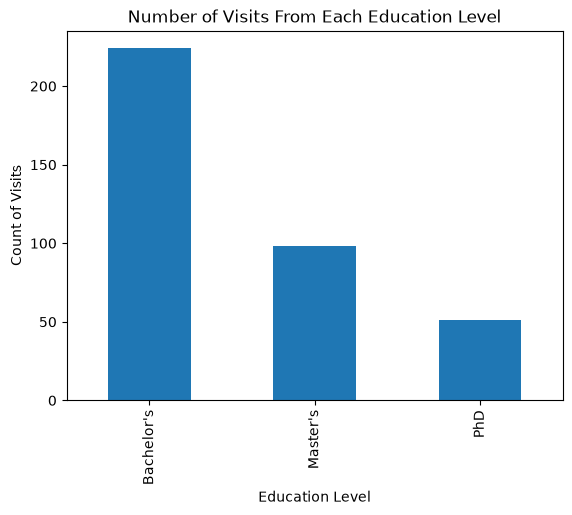

In [7]:
# bar chart of results - this part is done for you
df['Education Level'].value_counts().plot(kind='bar');
plt.title('Number of Visits From Each Education Level');
plt.ylabel('Count of Visits');
plt.show();

`e)` What are the possible values for `Salary`?  What does the distribution of `Salary` look like?

In [8]:
print(df['Salary'].describe())

count       373.000000
mean     100577.345845
std       48240.013482
min         350.000000
25%       55000.000000
50%       95000.000000
75%      140000.000000
max      250000.000000
Name: Salary, dtype: float64


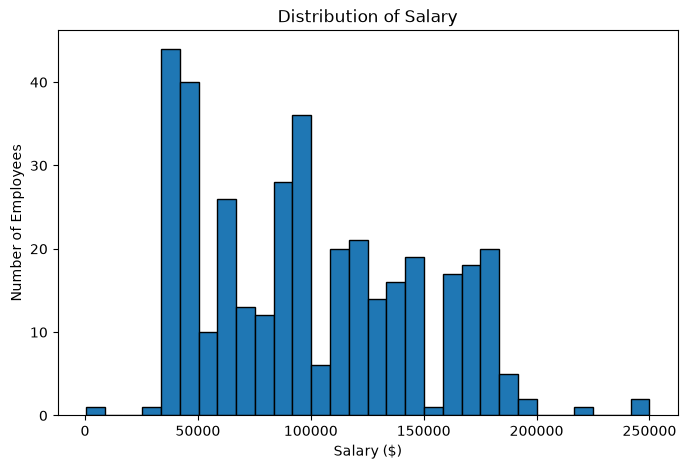

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df['Salary'], bins=30, edgecolor='black')
plt.title('Distribution of Salary')
plt.xlabel('Salary ($)')
plt.ylabel('Number of Employees')
plt.show()

<a id='regression'></a>
#### Part II - Regression

`1.` Now that you have had a chance to learn more about the dataset, let's look more at how different factors are related to `Salary`.

`a)` Consider average salary by gender, is there evidence that salaries are higher for one gender over the other?

In [10]:
# Average salary by gender
print(df.groupby('Gender')['Salary'].mean())
# Comment: male employees earn a higher average salary than female employees.

Gender
Female     97011.173184
Male      103867.783505
Name: Salary, dtype: float64


`b)` Consider average salary by education level, is there evidence that salaries are higher for increased education?

In [11]:
# Average salary by education level, highest first
print(df.groupby('Education Level')['Salary'].mean().sort_values(ascending=False))
# Comment: average salary rises with education - PhD > Master's > Bachelor's.

Education Level
PhD           157843.137255
Master's      129795.918367
Bachelor's     74756.026786
Name: Salary, dtype: float64


`c)` Consider average salary by years of experience, is there evidence that salaries are associated with increased years of experience?

                     Years of Experience    Salary
Years of Experience             1.000000  0.930338
Salary                          0.930338  1.000000


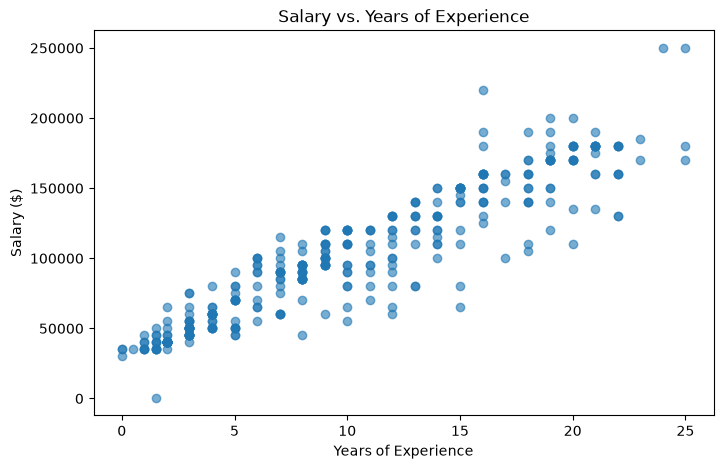

In [12]:
print(df[['Years of Experience', 'Salary']].corr())

plt.figure(figsize=(8, 5))
plt.scatter(df['Years of Experience'], df['Salary'], alpha=0.6)
plt.title('Salary vs. Years of Experience')
plt.xlabel('Years of Experience')
plt.ylabel('Salary ($)')
plt.show()
# Comment: the association is positive - more experience goes with higher salary.

`d)`  To make use of Job Title column lets create bool flag based on word existiance


List of words:

* Director
* Junior
* Senior
* Manager
* Analyst
* Engineer

**This question is completed for you**

In [13]:
flag_words = ['director', 'junior', 'senior', 'manager', 'analyst', 'engineer']
df['Job Title'] = df['Job Title'].str.lower()

for word in flag_words:
    df['is_' + word] = df['Job Title'].str.contains(word)
    
df = df.drop('Job Title', axis=1)

`e)` Create a flag for gender where 1 is if a person is male and 0 if the person is not.

In [14]:
df['is_male'] = (df['Gender'] == 'Male').astype(int)
df = df.drop('Gender', axis=1)
df.head()

,Age,Education Level,Years of Experience,Salary,is_director,is_junior,is_senior,is_manager,is_analyst,is_engineer,is_male
0,32.0,Bachelor's,5.0,90000.0,False,False,False,False,False,True,1
1,28.0,Master's,3.0,65000.0,False,False,False,False,True,False,0
2,45.0,PhD,15.0,150000.0,False,False,True,True,False,False,1
3,36.0,Bachelor's,7.0,60000.0,False,False,False,False,False,False,0
4,52.0,Master's,20.0,200000.0,True,False,False,False,False,False,1


`f)` Use statsmodels to fit a linear model to predict salary using each of the features from `a-e`.  These include:
* Gender
* Job TItle
* Years of Experience
* Education

In [15]:
# Dummy-code Education Level, using Bachelor's as the baseline
edu_dummies = pd.get_dummies(df['Education Level'], drop_first=True).astype(int)
edu_dummies = edu_dummies.rename(columns={"Master's": 'is_masters', 'PhD': 'is_phd'})
df = pd.concat([df.drop('Education Level', axis=1), edu_dummies], axis=1)

import statsmodels.api as sm

features = ['is_male', 'is_director', 'is_junior', 'is_senior', 'is_manager',
            'is_analyst', 'is_engineer', 'Years of Experience', 'is_masters', 'is_phd']

X = df[features].astype(float)
X = sm.add_constant(X)
y = df['Salary']

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.915
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     391.7
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          2.41e-187
Time:                        12:23:40   Log-Likelihood:                -4090.6
No. Observations:                 373   AIC:                             8203.
Df Residuals:                     362   BIC:                             8246.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                3.212e+04   2

<a id='interpretation'></a>
### Part III - Interpret Results

`1.` Consider you are tasked with finding which features in your linear model are significantly related to salary.  Were there any features that were not significantly related to salary in your first model?  If not, remove those features and fit a new model.  Only keep the features that were significant from the original model.

In [16]:
# Keep only the features whose p-value is 0.05 or lower in the full model (plus the constant)
significant = model.pvalues[model.pvalues <= 0.05].index.tolist()
dropped = [col for col in X.columns if col not in significant]
print('Dropped features (p > 0.05):', dropped)

X_reduced = X[significant]
model2 = sm.OLS(y, X_reduced).fit()
print(model2.summary())

Dropped features (p > 0.05): ['is_junior', 'is_analyst', 'is_engineer']
                            OLS Regression Results                            
Dep. Variable:                 Salary   R-squared:                       0.914
Model:                            OLS   Adj. R-squared:                  0.913
Method:                 Least Squares   F-statistic:                     557.4
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          1.46e-190
Time:                        12:23:40   Log-Likelihood:                -4092.6
No. Observations:                 373   AIC:                             8201.
Df Residuals:                     365   BIC:                             8233.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------

**Dropped variables (p > 0.05 in the first model):** `is_junior` (p = 0.068), `is_analyst` (p = 0.933), and `is_engineer` (p = 0.508). None of these title flags is statistically significantly related to salary at the 5% level, so they were removed from `X` to keep only the significant features (the constant was retained).

**Kept:** `const`, `is_male`, `is_director`, `is_senior`, `is_manager`, `Years of Experience`, `is_masters`, `is_phd` - all significant at p < 0.05 in the original model.

`a)` With each additional year of experience, what is the expected change in salary?  What is the 95% confidence interval of the change?

Each additional year of experience is associated with an expected salary increase of **$5,104** (coefficient = 5,104.44), holding gender, job-title flags, and education constant. The 95% confidence interval for this change is **[$4,755.93, $5,452.95]**. Because the interval lies entirely above zero, the association is statistically significant (p < 0.001): we can be 95% confident that the true per-year increase is between roughly $4,756 and $5,453.

`b)` What is the expected difference in salary between someone with a senior title and someone with none of the other title indications?

In the reduced model, having a senior title - compared with someone who has none of the other title indicators (not a director and not a manager) - is associated with an expected salary that is **$14,446 higher** (coefficient = 14,446.48; 95% CI [$10,867, $18,026]; p < 0.001), holding experience, gender, and education constant.

In practical terms, seniority carries a large salary premium: about 14% of the sample's average salary of roughly $100,577.

`c)` What is the expected difference in salary between someone with a PhD and an individual with no PhD nor master's degree?  What is the 95% confidence interval of the change?

Holding everything else constant, an individual with a PhD is expected to earn **$23,081 more** than someone with no PhD and no master's degree (the Bachelor's-degree baseline). The coefficient is 23,080.85, and its 95% confidence interval is **[$17,651.90, $28,509.80]**.

Since the interval excludes zero, the PhD premium is statistically significant (p < 0.001): we are 95% confident that the true premium is between about $17,652 and $28,510.

`d)` If a male employee has 5 years of experience as a senior engineer with a bachelor's degree, what is the expected salary of the employee?

In [17]:
# Build a single-row input: male, 5 years of experience, senior engineer, Bachelor's degree
profile = pd.DataFrame([{
    'const': 1,
    'is_male': 1,
    'is_director': 0,
    'is_senior': 1,
    'is_manager': 0,
    'Years of Experience': 5,
    'is_masters': 0,
    'is_phd': 0,
}])

# Align the columns with the reduced model's design matrix
profile = profile.reindex(columns=model2.params.index, fill_value=0)

predicted_salary = model2.predict(profile).iloc[0]
print(f'Predicted salary: ${predicted_salary:,.2f}')


Predicted salary: $76,359.11


The model predicts an expected salary of **$76,359.11** for a male employee with 5 years of experience, a senior engineer title, and a bachelor's degree.

Note: the `is_engineer` flag was not statistically significant in the full model (p = 0.51), so it was dropped when the reduced model was fit. The prediction therefore reflects the senior-title premium (plus the male, experience, and education terms) and does not change based on the engineer flag.

`e)` Imagine that the employee in question `d)` actually has a salary of $110,000, what would the residual be for this employee?

In [18]:
residual = 110000 - predicted_salary
print(f'Residual: ${residual:,.2f}')


Residual: $33,640.89


Residual = actual - predicted = 110,000 - 76,359.11 = **+$33,640.89**.

A positive residual means this employee earns about **$33,641 more** than the model expects for that profile - the model under-predicts this person's salary, which is consistent with the long right tail of the salary distribution.

`f)` How well do you think your model fits?  What metrics or plots would you consider to understand if this model does a good job of predicting salary?

R-squared: 0.9144608856149656
Adjusted R-squared: 0.9128204094486773


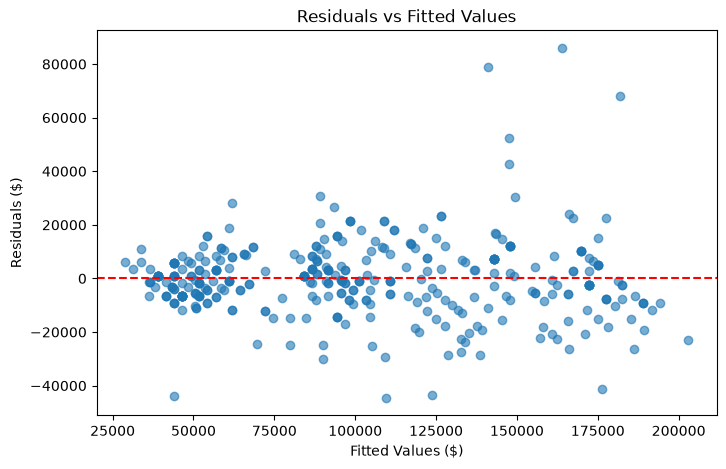

In [19]:
print('R-squared:', model2.rsquared)
print('Adjusted R-squared:', model2.rsquared_adj)

fitted = model2.fittedvalues
residuals = model2.resid

plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.title('Residuals vs Fitted Values')
plt.xlabel('Fitted Values ($)')
plt.ylabel('Residuals ($)')
plt.show()

The reduced model explains about **91.5%** of the variation in salary (R-squared = 0.9145; adjusted R-squared = 0.9128), which indicates a strong in-sample fit. R-squared alone, however, does not prove the model is correctly specified.

The residuals-vs-fitted plot shows no obvious curvature - the linear form looks reasonable, and residuals are roughly centered on zero at every fitted level (red line) - but the spread of the residuals clearly widens as fitted values increase, producing a funnel shape. The residual standard deviation grows from about $7.3k in the lowest fitted quartile to about $20k in the highest, so the constant-variance (homoscedasticity) assumption appears to be violated. There are also a few large positive outliers (actual salaries up to $250k) and the residual distribution is right-skewed (Jarque-Bera p < 0.001).

Practical implication: the coefficient estimates and point predictions are still useful, but the default OLS standard errors, confidence intervals, and p-values are not fully reliable. Using heteroscedasticity-robust standard errors (e.g. `model2.get_robustcov_results(cov_type='HC3')`) or modeling `log(Salary)` would be sensible improvements.

<a id='finalcheck'></a>
## Final Check!

Congratulations!  You have reached the end of the salary prediction project!  You should be very proud of all you have accomplished!

> **Tip**: Once you are satisfied with your work here, check over your notebook to make sure that it satisfies all the specifications mentioned in the rubric. You should also probably remove all of the "Hints" and "Tips" like this one so that the presentation is as polished as possible.


<a id='submission'></a>
## Submission

Please follow the directions in the classroom to submit this notebook, as well as your completed slides.